<a href="https://colab.research.google.com/github/Chaabmanal2022/-Google-Colab-SQLite/blob/main/Pipeline_2_Fixed_Reference_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **`Environment Setup & Library Imports`**

In [1]:
# ============================================================
# PYTHON STANDARD LIBRARIES
# ============================================================
import os
import time
import itertools
import gc
import json
import zipfile
import sqlite3
import warnings
from itertools import combinations
from contextlib import closing

# ============================================================
# DATA MANIPULATION AND STATISTICAL ANALYSIS
# ============================================================
import numpy as np
import pandas as pd

from scipy.stats import (
    spearmanr,
    pearsonr,
    variation
)
from scipy.spatial.distance import jensenshannon

# ============================================================
# DATA VISUALIZATION
# ============================================================
import matplotlib.pyplot as plt
import seaborn as sns

# ============================================================
# DATA PREPROCESSING AND CROSS-VALIDATION
# ============================================================
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold
)
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler
)
from sklearn.compose import ColumnTransformer
from sklearn.base import clone

# ============================================================
# MODEL PERFORMANCE AND EVALUATION METRICS
# ============================================================
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    jaccard_score
)
# ============================================================
# CLASS IMBALANCE HANDLING
# ============================================================
from imblearn.over_sampling import ADASYN

# ============================================================
# PREDICTIVE MODELING
# ============================================================
from xgboost import XGBClassifier

# ============================================================
# EXPLAINABLE ARTIFICIAL INTELLIGENCE (XAI)
# ============================================================
import shap

# ============================================================
# NOTEBOOK DISPLAY UTILITIES
# ============================================================
from IPython.display import display

# ============================================================
# GLOBAL CONFIGURATION
# ============================================================
warnings.filterwarnings("ignore")

# Graine globale (reproductibilité)
SEED = 42

# **`Data Loading & Setup`**

In [2]:
# Filename of the extracted PaySim CSV dataset
DATA_PATH = "PS_20174392719_1491204439457_log.csv"
# Filename of the compressed archive downloaded from Kaggle
ZIP_PATH  = "paysim1.zip"

# Check if the uncompressed CSV file already exists in the environment
if not os.path.exists(DATA_PATH):
    print("\n[INFO] Téléchargement du dataset via Kaggle API...")

    # Download the PaySim dataset directly using Kaggle API CLI
    os.system("kaggle datasets download -d ealaxi/paysim1")

    # If the ZIP file was downloaded successfully, extract its content
    if os.path.exists(ZIP_PATH):
        # Ouverture et extraction du fichier ZIP
        with zipfile.ZipFile(ZIP_PATH, 'r') as z:
            z.extractall(".")
        print("[INFO] Extraction terminée.")

    else:
        # Raise error if the download failed or API credentials are missing
        raise FileNotFoundError(
            "Le fichier ZIP PaySim est introuvable. "
            "Vérifiez votre configuration Kaggle."
        )
# Load data into pandas
df = pd.read_csv(DATA_PATH)


[INFO] Téléchargement du dataset via Kaggle API...
[INFO] Extraction terminée.


# **`Data Cleaning`**

In [3]:
# Garder uniquement les types de transaction qui contiennent des fraudes
print(f"Avant filtrage : {len(df):,} lignes | fraudes = {df['isFraud'].sum():,}")
df = df[df["type"].isin(["CASH_OUT", "TRANSFER"])].reset_index(drop=True)
print(f"Après filtrage : {len(df):,} lignes | fraudes = {df['isFraud'].sum():,}")

Avant filtrage : 6,362,620 lignes | fraudes = 8,213
Après filtrage : 2,770,409 lignes | fraudes = 8,213


# **`Feature & Target Definition`**

In [4]:
# Categorical and numerical feature columns
CATEGORICAL_FEATURES = ['type']
NUMERICAL_FEATURES   = [
    'step', 'amount',
    'oldbalanceOrg', 'newbalanceOrig',
    'oldbalanceDest', 'newbalanceDest'
]

TARGET = "isFraud"
FEATS  = CATEGORICAL_FEATURES + NUMERICAL_FEATURES

In [5]:
# 1) Train 80 % / Test 20 %  (stratifié)
train_df, test_df = train_test_split(df, test_size=0.20, stratify=df[TARGET], random_state=SEED)

# 2) Train -> Development 90 % / Fixed Reference 10 %  (stratifié)
dev_df, ref_df = train_test_split(train_df, test_size=0.10, stratify=train_df[TARGET], random_state=SEED)

X_dev,  y_dev  = dev_df[FEATS],  dev_df[TARGET]
X_ref,  y_ref  = ref_df[FEATS],  ref_df[TARGET]
X_test, y_test = test_df[FEATS], test_df[TARGET]

print(f"Development : {len(dev_df):,} ({int(y_dev.sum()):,} fraudes)")
print(f"Reference   : {len(ref_df):,} ({int(y_ref.sum()):,} fraudes)")
print(f"Test        : {len(test_df):,} ({int(y_test.sum()):,} fraudes)")

Development : 1,994,694 (5,913 fraudes)
Reference   : 221,633 (657 fraudes)
Test        : 554,082 (1,643 fraudes)


In [6]:
# Résumé des ensembles
datasets = {
    "Development (Cross-Validation)": (dev_df, "90 % du Train"),
    "Fixed Reference": (ref_df, "10 % du Train"),
    "Test": (test_df, "20 % du dataset initial")
}

rows = []

for name, (data, proportion) in datasets.items():
    total = len(data)
    fraud = int(data[TARGET].sum())
    legitimate = total - fraud

    rows.append({
        "Dataset": name,
        "Répartition": proportion,
        "Fraudes (1)": fraud,
        "Transactions légitimes (0)": legitimate,
        "Total transactions": total,
        "Fraud Rate": f"{data[TARGET].mean() * 100:.4f} %"
    })

summary = pd.DataFrame(rows)

# Ligne de total du Train (80 %)
train_total = len(train_df)
train_fraud = int(train_df[TARGET].sum())
train_legitimate = train_total - train_fraud

total_train_row = pd.DataFrame([{
    "Dataset": "TOTAL TRAIN (80 %)",
    "Répartition": "100 % du Train",
    "Fraudes (1)": train_fraud,
    "Transactions légitimes (0)": train_legitimate,
    "Total transactions": train_total,
    "Fraud Rate": f"{train_df[TARGET].mean() * 100:.4f} %"
}])

summary = pd.concat([summary, total_train_row], ignore_index=True)

# Affichage stylisé
styled_summary = (
    summary.style
    .hide(axis="index")
    .format({
        "Fraudes (1)": "{:,}",
        "Transactions légitimes (0)": "{:,}",
        "Total transactions": "{:,}"
    })
    .set_caption("PaySim Dataset — Train / Cross-Validation / Fixed Reference / Test")
    .set_properties(**{
        "text-align": "center",
        "padding": "12px",
        "border": "1px solid #D9E2F3"
    })
    .set_table_styles([
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("font-size", "17px"),
                ("font-weight", "bold"),
                ("color", "#24476B"),
                ("padding", "14px")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("background-color", "#24476B"),
                ("color", "white"),
                ("font-weight", "bold"),
                ("text-align", "center"),
                ("padding", "12px")
            ]
        },
        {
            "selector": "tbody tr:last-child",
            "props": [
                ("background-color", "#DCE6F1"),
                ("font-weight", "bold"),
                ("border-top", "2px solid #24476B"
                )
            ]
        }
    ])
)

display(styled_summary)

Dataset,Répartition,Fraudes (1),Transactions légitimes (0),Total transactions,Fraud Rate
Development (Cross-Validation),90 % du Train,"5,913","1,988,781","1,994,694",0.2964 %
Fixed Reference,10 % du Train,657,"220,976","221,633",0.2964 %
Test,20 % du dataset initial,"1,643","552,439","554,082",0.2965 %
TOTAL TRAIN (80 %),100 % du Train,"6,570","2,209,757","2,216,327",0.2964 %


# **`Paysim Dataset - Data Partitioning`**

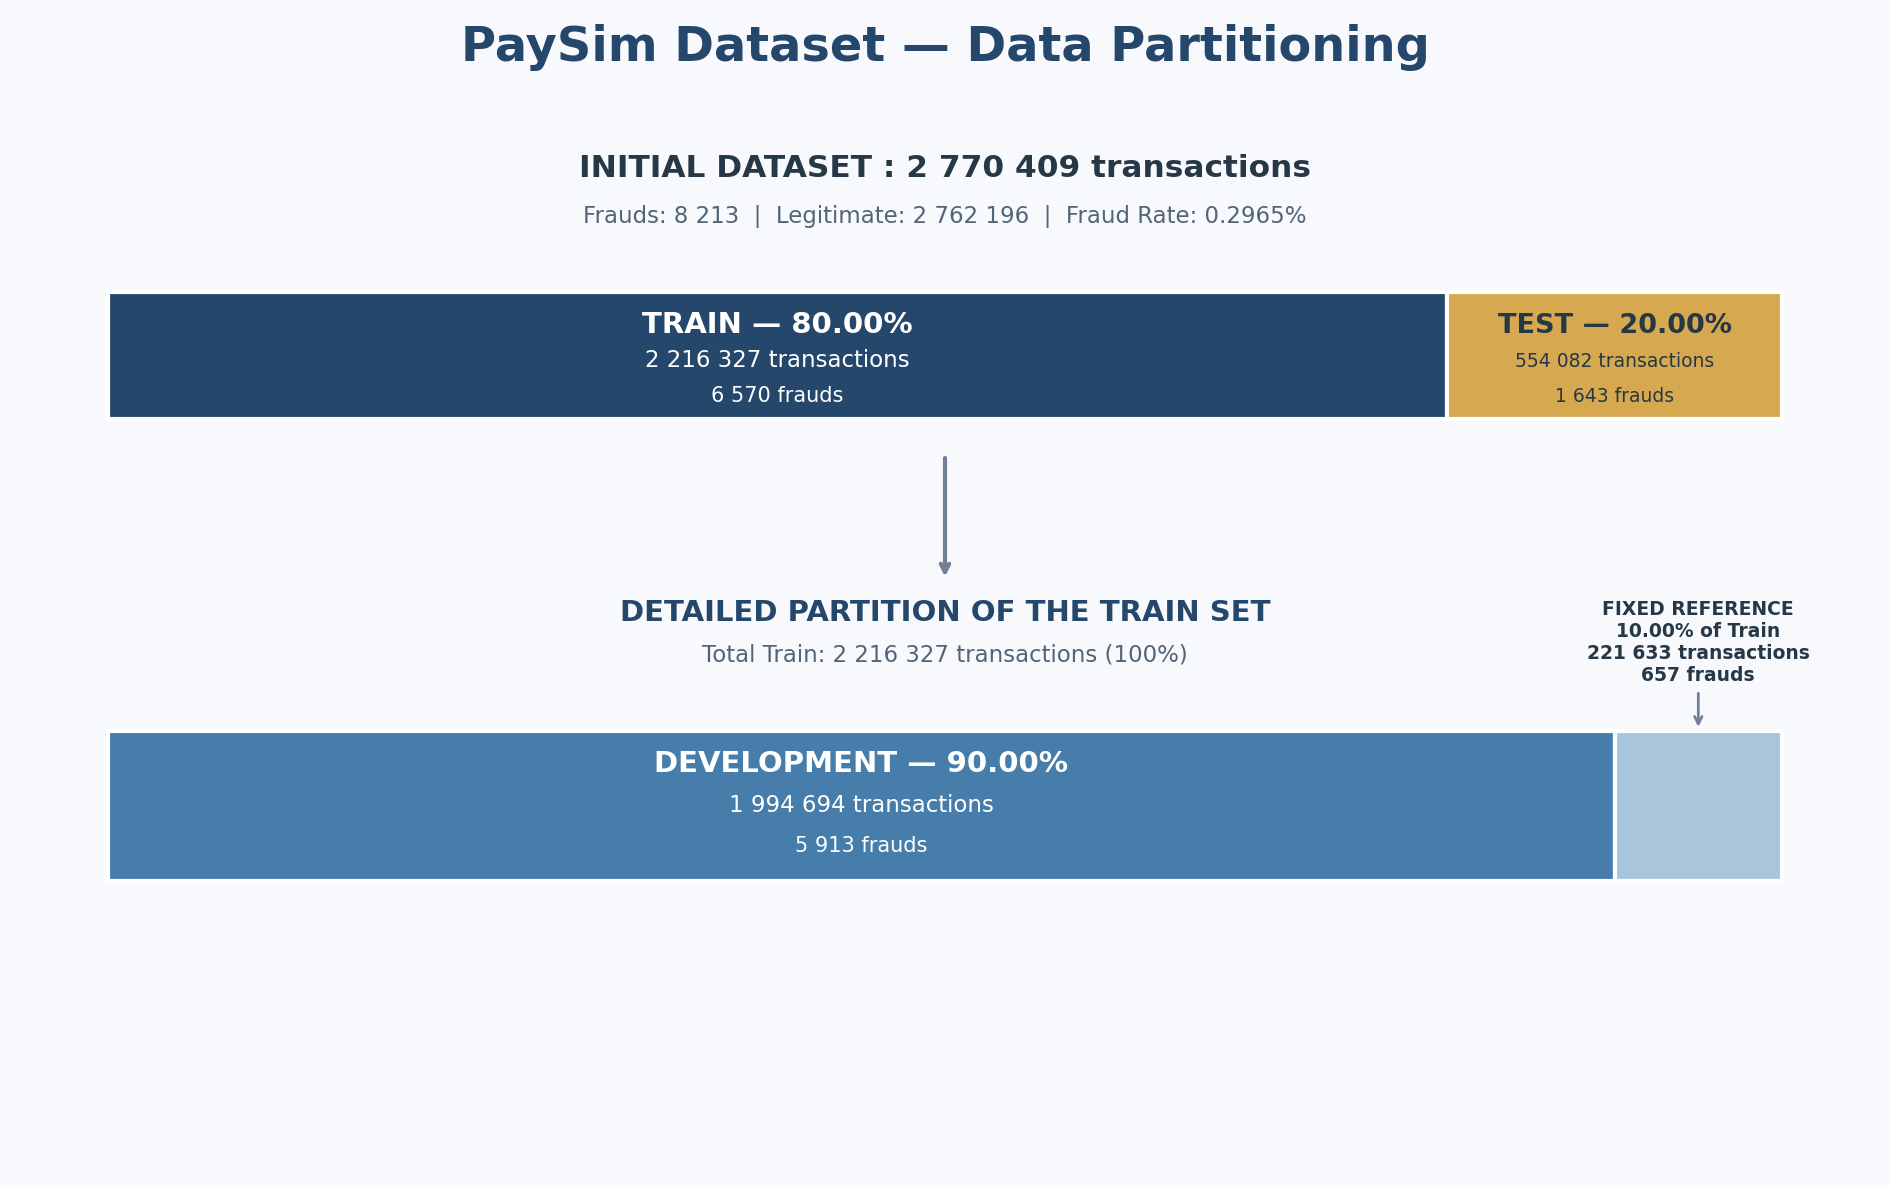

Schéma généré et enregistré : PaySim_Data_Partitioning.png


In [7]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# ============================================================
# 1. RÉCUPÉRATION DES EFFECTIFS RÉELS
# ============================================================

def get_stats(data):
    total = len(data)
    fraud = int(data[TARGET].sum())
    legitimate = total - fraud

    return {
        "total": total,
        "fraud": fraud,
        "legitimate": legitimate,
        "rate": fraud / total * 100
    }

initial = get_stats(df)
train = get_stats(train_df)
test = get_stats(test_df)
dev = get_stats(dev_df)
ref = get_stats(ref_df)

def fmt(n):
    return f"{n:,}".replace(",", " ")

# ============================================================
# 2. CONFIGURATION DU SCHÉMA
# ============================================================

fig, ax = plt.subplots(figsize=(16, 10), dpi=150)

fig.patch.set_facecolor("#F7F9FC")
ax.set_facecolor("#F7F9FC")

ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.axis("off")

# Palette professionnelle
NAVY = "#24476B"
BLUE = "#477DAA"
LIGHT_BLUE = "#A9C5DC"
GOLD = "#D6A84F"
DARK = "#263746"
WHITE = "#FFFFFF"

# ============================================================
# 3. TITRE ET INFORMATIONS DU DATASET INITIAL
# ============================================================

ax.text(
    50, 96,
    "PaySim Dataset — Data Partitioning",
    ha="center", fontsize=23,
    fontweight="bold", color=NAVY
)


ax.text(
    50, 86,
    f"INITIAL DATASET : {fmt(initial['total'])} transactions",
    ha="center", fontsize=15,
    fontweight="bold", color=DARK
)

ax.text(
    50, 82,
    f"Frauds: {fmt(initial['fraud'])}  |  "
    f"Legitimate: {fmt(initial['legitimate'])}  |  "
    f"Fraud Rate: {initial['rate']:.4f}%",
    ha="center", fontsize=11, color="#526477"
)

# ============================================================
# 4. PREMIÈRE PARTITION : TRAIN / TEST
#    Largeurs proportionnelles aux effectifs réels
# ============================================================

x_start = 5
total_width = 90
y_top = 65
height_top = 11

train_width = total_width * train["total"] / initial["total"]
test_width = total_width * test["total"] / initial["total"]

# Bloc TRAIN
ax.add_patch(Rectangle(
    (x_start, y_top), train_width, height_top,
    facecolor=NAVY, edgecolor=WHITE, linewidth=2
))

# Bloc TEST
ax.add_patch(Rectangle(
    (x_start + train_width, y_top), test_width, height_top,
    facecolor=GOLD, edgecolor=WHITE, linewidth=2
))

# Informations TRAIN
ax.text(
    x_start + train_width / 2, y_top + 7.5,
    f"TRAIN — {train['total']/initial['total']*100:.2f}%",
    ha="center", fontsize=14, fontweight="bold", color=WHITE
)

ax.text(
    x_start + train_width / 2, y_top + 4.5,
    f"{fmt(train['total'])} transactions",
    ha="center", fontsize=11, color=WHITE
)

ax.text(
    x_start + train_width / 2, y_top + 1.5,
    f"{fmt(train['fraud'])} frauds",
    ha="center", fontsize=10, color=WHITE
)

# Informations TEST
ax.text(
    x_start + train_width + test_width / 2, y_top + 7.5,
    f"TEST — {test['total']/initial['total']*100:.2f}%",
    ha="center", fontsize=13, fontweight="bold", color=DARK
)

ax.text(
    x_start + train_width + test_width / 2, y_top + 4.5,
    f"{fmt(test['total'])} transactions",
    ha="center", fontsize=9, color=DARK
)

ax.text(
    x_start + train_width + test_width / 2, y_top + 1.5,
    f"{fmt(test['fraud'])} frauds",
    ha="center", fontsize=9, color=DARK
)

# ============================================================
# 5. FLÈCHE VERS LA DEUXIÈME PARTITION
# ============================================================

ax.annotate(
    "",
    xy=(50, 51),
    xytext=(50, 62),
    arrowprops=dict(arrowstyle="->", color="#718096", lw=2)
)

ax.text(
    50, 47.5,
    "DETAILED PARTITION OF THE TRAIN SET",
    ha="center", fontsize=14,
    fontweight="bold", color=NAVY
)

ax.text(
    50, 44,
    f"Total Train: {fmt(train['total'])} transactions (100%)",
    ha="center", fontsize=11, color="#526477"
)

# ============================================================
# 6. DEUXIÈME PARTITION : DEVELOPMENT / FIXED REFERENCE
#    Largeurs proportionnelles au Train réel
# ============================================================

y_bottom = 25
height_bottom = 13

dev_width = total_width * dev["total"] / train["total"]
ref_width = total_width * ref["total"] / train["total"]

# Bloc DEVELOPMENT
ax.add_patch(Rectangle(
    (x_start, y_bottom), dev_width, height_bottom,
    facecolor=BLUE, edgecolor=WHITE, linewidth=2
))

# Bloc FIXED REFERENCE
ax.add_patch(Rectangle(
    (x_start + dev_width, y_bottom), ref_width, height_bottom,
    facecolor=LIGHT_BLUE, edgecolor=WHITE, linewidth=2
))

# Informations DEVELOPMENT
ax.text(
    x_start + dev_width / 2, y_bottom + 9.5,
    f"DEVELOPMENT — {dev['total']/train['total']*100:.2f}%",
    ha="center", fontsize=14, fontweight="bold", color=WHITE
)

ax.text(
    x_start + dev_width / 2, y_bottom + 6,
    f"{fmt(dev['total'])} transactions",
    ha="center", fontsize=11, color=WHITE
)

ax.text(
    x_start + dev_width / 2, y_bottom + 2.5,
    f"{fmt(dev['fraud'])} frauds",
    ha="center", fontsize=10, color=WHITE
)

# Informations FIXED REFERENCE
# Le bloc est étroit : on utilise une annotation externe
ax.annotate(
    f"FIXED REFERENCE\n"
    f"{ref['total']/train['total']*100:.2f}% of Train\n"
    f"{fmt(ref['total'])} transactions\n"
    f"{fmt(ref['fraud'])} frauds",
    xy=(x_start + dev_width + ref_width / 2, y_bottom + height_bottom),
    xytext=(x_start + dev_width + ref_width / 2, 42),
    ha="center",
    va="bottom",
    fontsize=9,
    fontweight="bold",
    color=DARK,
    arrowprops=dict(arrowstyle="->", color="#718096", lw=1.3)
)

# ============================================================
# 8. ENREGISTREMENT ET AFFICHAGE
# ============================================================

plt.savefig(
    "PaySim_Data_Partitioning.png",
    dpi=300,
    bbox_inches="tight",
    facecolor=fig.get_facecolor()
)

plt.show()

print("Schéma généré et enregistré : PaySim_Data_Partitioning.png")

## **`Fixed Reference Dataset Configuration & Sampling`**

In [8]:
# une proportion de 50 % de fraudes et 50 % de transactions légitimes.
REF_MODE = "balanced"

if REF_MODE == "balanced":
    # sélectionner des transactions légitimes aléatoirement, mais obtenir toujours le même échantillon lorsque je relance notebook.
    rng = np.random.RandomState(SEED)
    # récupère les indices des positions correspondant aux fraudes.
    idx_fraud = np.where(y_ref.values == 1)[0]
    # Sélectionner autant de transactions légitimes
    idx_legit = rng.choice(np.where(y_ref.values == 0)[0], size=len(idx_fraud), replace=False)
    # Fusionner les deux groupes
    idx_ref = np.sort(np.concatenate([idx_fraud, idx_legit]))
# sélectionne toutes les observations de X_ref, sans effectuer aucun échantillonnage
else:
    idx_ref = np.arange(len(X_ref))
# sélectionner les mêmes lignes dans les variables X_ref et y_ref, en utilisant les indices contenus dans idx_ref
X_ref_s, y_ref_s = X_ref.iloc[idx_ref], y_ref.iloc[idx_ref]

print(f"Fixed Reference ({REF_MODE}) : {len(X_ref_s):,} transactions | "
      f"{int(y_ref_s.sum()):,} fraudes ({y_ref_s.mean():.2%}) | "
      f"{int((y_ref_s == 0).sum()):,} légitimes")

Fixed Reference (balanced) : 1,314 transactions | 657 fraudes (50.00%) | 657 légitimes


***`Feature Preprocessing Pipeline Setup`***

In [9]:
preprocessor = ColumnTransformer(
    [("categorical",
      OneHotEncoder(handle_unknown="ignore", sparse_output=False),
      CATEGORICAL_FEATURES)],
    remainder="passthrough", verbose_feature_names_out=False)

***`Stratified Cross-Validation Setup (5-Fold CV)`***

In [10]:
INNER_CV  = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
CV_SPLITS = list(INNER_CV.split(X_dev, y_dev))

In [11]:

# ============================================================
# 1. CALCUL DE LA DISTRIBUTION DES CLASSES
# ============================================================

results = []

for fold, (_, val_idx) in enumerate(CV_SPLITS, 1):

    y_fold = y_dev.iloc[val_idx]

    counts = y_fold.value_counts().reindex([0, 1], fill_value=0)

    percentages = (
        y_fold.value_counts(normalize=True)
        .reindex([0, 1], fill_value=0) * 100
    )

    results.append({
        "Dataset": f"Fold {fold}",
        "Total Transactions": len(y_fold),
        "Legitimate Cases": counts[0],
        "Legitimate (%)": percentages[0],
        "Fraud Cases": counts[1],
        "Fraud (%)": percentages[1]
    })

# ============================================================
# 2. CRÉATION DU DATAFRAME
# ============================================================

fold_distribution_df = pd.DataFrame(results)

# ============================================================
# 3. STYLISATION PROFESSIONNELLE
# ============================================================

styled_fold_table = (
    fold_distribution_df.style
    .hide(axis="index")
    .format({
        "Total Transactions": "{:,.0f}",
        "Legitimate Cases": "{:,.0f}",
        "Legitimate (%)": "{:.4f}%",
        "Fraud Cases": "{:,.0f}",
        "Fraud (%)": "{:.4f}%"
    })
    .set_caption("Class Distribution Across 5 Validation Folds")
    .set_properties(**{
        "text-align": "center",
        "padding": "10px",
        "border": "1px solid #D9E2F3"
    })
    .set_table_styles([
        {
            "selector": "caption",
            "props": [
                ("caption-side", "top"),
                ("font-size", "16px"),
                ("font-weight", "bold"),
                ("color", "#1F4E79"),
                ("padding", "12px")
            ]
        },
        {
            "selector": "th",
            "props": [
                ("background-color", "#D9EAF7"),
                ("color", "#1F1F1F"),
                ("font-weight", "bold"),
                ("text-align", "center"),
                ("padding", "10px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("text-align", "center")
            ]
        }
    ])
)

# ============================================================
# 4. AFFICHAGE
# ============================================================

display(styled_fold_table)

Dataset,Total Transactions,Legitimate Cases,Legitimate (%),Fraud Cases,Fraud (%)
Fold 1,"398,939","397,757",99.7037%,"1,182",0.2963%
Fold 2,"398,939","397,756",99.7035%,"1,183",0.2965%
Fold 3,"398,939","397,756",99.7035%,"1,183",0.2965%
Fold 4,"398,939","397,756",99.7035%,"1,183",0.2965%
Fold 5,"398,938","397,756",99.7037%,"1,182",0.2963%


In [12]:
XGB_T17 = dict(n_estimators=423, max_depth=6, learning_rate=0.04401514622528401,
               subsample=0.8203514588078392, colsample_bytree=0.9928885066883009,
               gamma=3.841293320583421, min_child_weight=5,
               eval_metric="aucpr", random_state=SEED, n_jobs=-1)

FULL_GRID = True    # True : grille complète | False : sous-ensemble rapide

K_NEIGHBORS = list(range(5, 26))                                  # 5, 6, 7, ..., 25  (21 valeurs)
STRATEGIES  = [round(0.1 * i, 1) for i in range(1, 11)]           # 0.1, 0.2, ..., 1.0 (10 valeurs)

if FULL_GRID:
    # baseline (k=0, sans ADASYN) + 21 x 10 = 210 configs ADASYN  ->  211 configs
    CONFIGS = [(0, 0.0)] + list(itertools.product(K_NEIGHBORS, STRATEGIES))
else:
    CONFIGS = [(0, 0.0), (5, 0.2), (15, 0.5), (25, 1.0)]

print(f"{len(CONFIGS)} configurations x 5 folds = {len(CONFIGS) * 5} modèles XGBoost")

211 configurations x 5 folds = 1055 modèles XGBoost


In [13]:
def compute_shap_ref(model, X_ref_prep):
    """Importance globale = moyenne des |SHAP| sur TOUTE la référence fixe."""
    sv = shap.TreeExplainer(model).shap_values(X_ref_prep)
    if isinstance(sv, list):  sv = sv[1]
    elif sv.ndim == 3:        sv = sv[:, :, 1]
    return np.abs(sv).mean(axis=0)


def calculate_stability(vectors, top_k=3):
    """vectors : un vecteur d'importance SHAP par fold (mêmes features, même ordre)."""
    vectors = [np.asarray(v, dtype=float) for v in vectors]
    sp, jac, js = [], [], []
    for a, b in combinations(vectors, 2):
        sp.append(spearmanr(a, b).statistic)                         # haut = stable
        ta, tb = set(np.argsort(a)[-top_k:]), set(np.argsort(b)[-top_k:])
        jac.append(len(ta & tb) / len(ta | tb))                       # haut = stable
        p, q = a + 1e-12, b + 1e-12
        js.append(jensenshannon(p / p.sum(), q / q.sum(), base=2))   # bas = stable
    M = np.vstack(vectors)
    cv = np.mean(M.std(axis=0) / (M.mean(axis=0) + 1e-12))            # bas = stable
    return dict(spearman=np.nanmean(sp), top3_jaccard=np.mean(jac), js=np.mean(js), cv=cv)

In [14]:
try:
    from google.colab import drive
    drive.mount("/content/drive"); OUT_DIR = "/content/drive/MyDrive"
except ImportError:
    OUT_DIR = "."

DB = f"{OUT_DIR}/Pipeline2_FixedRef.db"

# Sauvegarde des indices de la référence (pour reproductibilité)
np.save(f"{OUT_DIR}/fixed_reference_indices.npy", ref_df.index[idx_ref].values)

with closing(sqlite3.connect(DB, timeout=60)) as c:
    c.execute("""CREATE TABLE IF NOT EXISTS grid_folds (
        n_neighbors INTEGER, sampling_strategy REAL, fold INTEGER,
        pr_auc REAL, shap_importance TEXT, duration REAL,
        PRIMARY KEY (n_neighbors, sampling_strategy, fold))""")

def load_folds(k, s):
    with closing(sqlite3.connect(DB, timeout=60)) as c:
        return pd.read_sql_query(
            "SELECT * FROM grid_folds WHERE n_neighbors=? AND sampling_strategy=? ORDER BY fold",
            c, params=(k, s))

def save_fold(k, s, fold, pr_auc, shap_imp, duration):
    with closing(sqlite3.connect(DB, timeout=60)) as c:
        c.execute("INSERT OR REPLACE INTO grid_folds VALUES (?,?,?,?,?,?)",
                  (k, s, fold, float(pr_auc), json.dumps([float(v) for v in shap_imp]), float(duration)))
        c.commit()

Mounted at /content/drive


In [15]:
def run_fold(k, s, fold, tr, va):
    # Preprocessing fitté sur le train du fold uniquement
    prep    = clone(preprocessor)
    X_tr    = prep.fit_transform(X_dev.iloc[tr], y_dev.iloc[tr])
    X_val   = prep.transform(X_dev.iloc[va])
    X_ref_p = prep.transform(X_ref_s)              # même référence pour tous les modèles
    y_tr, y_val = y_dev.iloc[tr], y_dev.iloc[va]

    # ADASYN uniquement sur le train du fold (k = 0 -> baseline sans ADASYN)
    if k > 0:
        X_tr, y_tr = ADASYN(n_neighbors=k, sampling_strategy=s,
                            random_state=SEED + fold).fit_resample(X_tr, y_tr)

    model    = XGBClassifier(**XGB_T17).fit(X_tr, y_tr)
    pr_auc   = average_precision_score(y_val, model.predict_proba(X_val)[:, 1])
    shap_imp = compute_shap_ref(model, X_ref_p)
    return pr_auc, shap_imp


def run_config(k, s):
    done = set(load_folds(k, s)["fold"])           # reprise : on saute les folds déjà calculés
    for fold, (tr, va) in enumerate(CV_SPLITS, start=1):
        if fold in done:
            continue
        t0 = time.time()
        pr_auc, shap_imp = run_fold(k, s, fold, tr, va)
        save_fold(k, s, fold, pr_auc, shap_imp, time.time() - t0)
        print(f"   fold {fold} | PR-AUC={pr_auc:.5f} | {time.time()-t0:.0f}s")
        gc.collect()


def summarize(k, s):
    g = load_folds(k, s)
    vecs = [json.loads(x) for x in g["shap_importance"]]
    return dict(n_neighbors=k, sampling_strategy=s,
                pr_auc=g["pr_auc"].mean(), pr_auc_std=g["pr_auc"].std(ddof=1),
                **calculate_stability(vecs))

In [ ]:
results, base = [], None
for k, s in CONFIGS:
    print(f"=== n_neighbors={k} | sampling_strategy={s} ===")
    run_config(k, s)
    r = summarize(k, s)
    results.append(r)
    if k == 0:
        base = r
    print(f"→ PR-AUC={r['pr_auc']:.5f} | Spearman={r['spearman']:.4f} | "
          f"Top3-Jac={r['top3_jaccard']:.3f} | JS={r['js']:.4f} | CV={r['cv']:.4f}\n")

df_results = pd.DataFrame(results)
for m in ["pr_auc", "spearman", "top3_jaccard", "js", "cv"]:
    df_results[f"delta_{m}"] = df_results[m] - base[m]      # écart vs baseline sans ADASYN
df_results.round(5)

=== n_neighbors=0 | sampling_strategy=0.0 ===
→ PR-AUC=0.95094 | Spearman=0.9857 | Top3-Jac=1.000 | JS=0.0241 | CV=0.0531

=== n_neighbors=5 | sampling_strategy=0.1 ===
→ PR-AUC=0.96639 | Spearman=0.9762 | Top3-Jac=0.800 | JS=0.0268 | CV=0.0588

=== n_neighbors=5 | sampling_strategy=0.2 ===
→ PR-AUC=0.96511 | Spearman=0.9595 | Top3-Jac=0.800 | JS=0.0813 | CV=0.1599

=== n_neighbors=5 | sampling_strategy=0.3 ===
→ PR-AUC=0.96427 | Spearman=0.9476 | Top3-Jac=0.800 | JS=0.0703 | CV=0.1500

=== n_neighbors=5 | sampling_strategy=0.4 ===
→ PR-AUC=0.96382 | Spearman=0.9143 | Top3-Jac=0.800 | JS=0.0629 | CV=0.1341

=== n_neighbors=5 | sampling_strategy=0.5 ===
→ PR-AUC=0.96348 | Spearman=0.9595 | Top3-Jac=0.800 | JS=0.0475 | CV=0.0999

=== n_neighbors=5 | sampling_strategy=0.6 ===
→ PR-AUC=0.96155 | Spearman=0.9595 | Top3-Jac=0.800 | JS=0.0342 | CV=0.0735

=== n_neighbors=5 | sampling_strategy=0.7 ===
→ PR-AUC=0.96163 | Spearman=0.9310 | Top3-Jac=0.800 | JS=0.0538 | CV=0.1116

=== n_neighbors=